# CNN+LSTM v2 Evaluation
# Input:  CNN_LSTM_results_v2/cnn_lstm_v2_best.pt
#         CNN_LSTM_results_v2/sensor_stats.csv
#         traffic_features_v3.parquet
# Output: CNN_LSTM_results_v2/cnn_lstm_v2_results.json
#         CNN_LSTM_figures_v2/ (all figures)
# Thesis: Chapter 7 (Experimental Results — CNN+LSTM)

In [1]:
import os
import json
import time
import warnings
warnings.filterwarnings("ignore")

import duckdb
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

# ── Reproducibility ────────────────────────────────────────────────────────────
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    torch.set_float32_matmul_precision("medium")

# ── Paths ──────────────────────────────────────────────────────────────────────
FEATURES_PATH = "/home/iai-labor/traffic_project/traffic_features_v3.parquet"
RESULTS_DIR   = "/home/iai-labor/traffic_project/CNN_LSTM_results_v2"
FIGURES_DIR   = "/home/iai-labor/traffic_project/CNN_LSTM_figures_v2"
CHECKPOINT    = "/home/iai-labor/traffic_project/CNN_LSTM_results_v2/cnn_lstm_v2_best.pt"
os.makedirs(FIGURES_DIR, exist_ok=True)

SUBCLASS_NAMES = {0: "URB_normal", 1: "URB_ramp", 2: "M30", 3: "C30"}

# ── Verify checkpoint ──────────────────────────────────────────────────────────
assert os.path.exists(CHECKPOINT), f"Checkpoint not found: {CHECKPOINT}"
ckpt_size_mb = os.path.getsize(CHECKPOINT) / 1e6
print(f"Checkpoint confirmed: {CHECKPOINT}")
print(f"Size: {ckpt_size_mb:.1f} MB")

# ── Load training config ───────────────────────────────────────────────────────
with open(os.path.join(RESULTS_DIR, "cnn_lstm_v2_config.json")) as f:
    saved = json.load(f)

CFG          = saved["config"]
FEATURE_COLS = saved["feature_cols"]
N_FEATURES   = saved["n_features"]

print(f"\nConfig loaded from training:")
print(f"  encoder_length:    {CFG['max_encoder_length']}h")
print(f"  prediction_length: {CFG['max_prediction_length']}h")
print(f"  n_features:        {N_FEATURES}")
print(f"  dropout:           {CFG['dropout']}")
print(f"  lr:                {CFG['lr']}")
print(f"  best_val_loss:     {saved['best_val_loss']:.4f} z-score MAE")
print(f"  epochs_run:        {saved['epochs_run']}")
print(f"  train_minutes:     {saved['train_minutes']:.1f}")
print(f"  train_loss_method: {saved['train_loss_method']}")

Device: cuda
GPU: NVIDIA RTX A2000 12GB
Checkpoint confirmed: /home/iai-labor/traffic_project/CNN_LSTM_results_v2/cnn_lstm_v2_best.pt
Size: 1.0 MB

Config loaded from training:
  encoder_length:    48h
  prediction_length: 6h
  n_features:        29
  dropout:           0.1
  lr:                0.0001
  best_val_loss:     0.1460 z-score MAE
  epochs_run:        44
  train_minutes:     212.3
  train_loss_method: FrozenTrainEval


In [2]:
# ── Load SENSOR_STATS saved during training ────────────────────────────────────
SENSOR_STATS = pd.read_csv(
    os.path.join(RESULTS_DIR, "sensor_stats.csv"),
    index_col="SENSOR_ID"
)
print(f"SENSOR_STATS loaded: {len(SENSOR_STATS)} sensors")
print(f"μ range: {SENSOR_STATS['mu'].min():.1f} – {SENSOR_STATS['mu'].max():.1f} veh/h")
print(f"σ range: {SENSOR_STATS['sigma'].min():.1f} – {SENSOR_STATS['sigma'].max():.1f} veh/h")

# ── Reload data — identical pipeline to training ───────────────────────────────
con = duckdb.connect()

sampled = con.sql(f"""
    WITH ranked AS (
        SELECT SENSOR_ID, road_subclass_enc, COUNT(*) AS n_obs,
               ROW_NUMBER() OVER (
                   PARTITION BY road_subclass_enc
                   ORDER BY COUNT(*) DESC, SENSOR_ID ASC
               ) AS rn
        FROM read_parquet('{FEATURES_PATH}')
        WHERE split    = 'train'
          AND target   IS NOT NULL
          AND lag_1h   IS NOT NULL
          AND lag_168h IS NOT NULL
        GROUP BY SENSOR_ID, road_subclass_enc
        HAVING COUNT(*) > 8760
    )
    SELECT SENSOR_ID, road_subclass_enc, n_obs
    FROM ranked
    WHERE rn <= {CFG['sensors_per_class']}
    ORDER BY road_subclass_enc, SENSOR_ID
""").df()

SENSOR_IDS = sampled["SENSOR_ID"].tolist()
id_list    = ",".join(map(str, SENSOR_IDS))
print(f"\nSensors: {len(SENSOR_IDS)} ({CFG['sensors_per_class']} per sub-class)")

# ── Load data ──────────────────────────────────────────────────────────────────
print("Loading data...")
t0 = time.time()

df = con.sql(f"""
    SELECT SENSOR_ID, DATETIME, target, road_subclass_enc, split,
           longitude, latitude, is_main_artery,
           dist_station_km, dist_stadium_km, dist_hospital_km,
           dist_university_km, dist_mall_km, dist_bus_station_km,
           near_major_poi,
           hour_sin, hour_cos, dow_sin, dow_cos,
           month_sin, month_cos,
           is_weekend, is_holiday, is_rush_hour, season,
           lag_1h, lag_2h, lag_3h, lag_24h, lag_168h,
           roll_mean_3h, roll_mean_24h
    FROM read_parquet('{FEATURES_PATH}')
    WHERE SENSOR_ID IN ({id_list})
      AND target IS NOT NULL
      AND lag_1h IS NOT NULL
    ORDER BY SENSOR_ID, DATETIME
""").df()

df["DATETIME"]   = pd.to_datetime(df["DATETIME"])
df               = df.sort_values(["SENSOR_ID","DATETIME"]).reset_index(drop=True)
df["sensor_str"] = df["SENSOR_ID"].astype(str)
print(f"Loaded: {len(df):,} rows in {time.time()-t0:.1f}s")

# ── Time index ─────────────────────────────────────────────────────────────────
time_origin    = df["DATETIME"].min()
df["time_idx"] = (
    (df["DATETIME"] - time_origin)
    .dt.total_seconds().div(3600).round().astype(int)
)
train_end_idx = int(
    (pd.Timestamp(CFG["train_end"]) - time_origin).total_seconds() / 3600
)
val_end_idx = int(
    (pd.Timestamp(CFG["val_end"]) - time_origin).total_seconds() / 3600
)
BUFFER = CFG["max_encoder_length"]  # 48h

print(f"time_origin:   {time_origin}")
print(f"train_end_idx: {train_end_idx}")
print(f"val_end_idx:   {val_end_idx}")
print(f"Buffer:        {BUFFER}h")

# ── Apply normalisation — MUST use training SENSOR_STATS ──────────────────────
df["mu_i"]    = df["SENSOR_ID"].map(SENSOR_STATS["mu"])
df["sigma_i"] = df["SENSOR_ID"].map(SENSOR_STATS["sigma"])

LAG_COLS_RAW = [
    "lag_1h","lag_2h","lag_3h","lag_24h","lag_168h",
    "roll_mean_3h","roll_mean_24h"
]
LAG_COLS_NORM = [
    "lag_1h_norm","lag_2h_norm","lag_3h_norm","lag_24h_norm","lag_168h_norm",
    "roll_mean_3h_norm","roll_mean_24h_norm"
]
TARGET_COLS = ["target"] + LAG_COLS_RAW
NORM_COLS   = ["target_norm"] + LAG_COLS_NORM

for raw_col, norm_col in zip(TARGET_COLS, NORM_COLS):
    df[norm_col] = (df[raw_col] - df["mu_i"]) / df["sigma_i"]

# ── Test split ─────────────────────────────────────────────────────────────────
static_cols = [
    "longitude","latitude","is_main_artery",
    "dist_station_km","dist_stadium_km","dist_hospital_km",
    "dist_university_km","dist_mall_km","dist_bus_station_km",
    "near_major_poi",
]
df_test = df[df["time_idx"] > val_end_idx - BUFFER].copy()

for col in static_cols:
    if df_test[col].isna().any():
        fill_val = float(df[col].median())
        df_test[col] = df_test[col].fillna(fill_val)

df_test = df_test.dropna(subset=LAG_COLS_RAW).reset_index(drop=True)
print(f"\nTest split size: {len(df_test):,} rows")

SENSOR_STATS loaded: 200 sensors
μ range: 28.6 – 3924.1 veh/h
σ range: 12.8 – 2451.4 veh/h

Sensors: 200 (50 per sub-class)
Loading data...
Loaded: 5,981,000 rows in 4.9s
time_origin:   2023-01-01 01:00:00
train_end_idx: 21167
val_end_idx:   25559
Buffer:        48h

Test split size: 878,600 rows


In [3]:
# ── CNN+LSTM model definition — must match training exactly ───────────────────
class CNNLSTMForecaster(nn.Module):
    def __init__(self, n_features, pred_len, cfg):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(
                in_channels  = n_features,
                out_channels = cfg["cnn_filters"],
                kernel_size  = cfg["cnn_kernel"],
                padding      = cfg["cnn_kernel"] // 2,
            ),
            nn.BatchNorm1d(cfg["cnn_filters"]),
            nn.ReLU(),
            nn.Dropout(cfg["dropout"]),
        )
        self.lstm = nn.LSTM(
            input_size  = cfg["cnn_filters"],
            hidden_size = cfg["lstm_hidden"],
            num_layers  = cfg["lstm_layers"],
            batch_first = True,
            dropout     = cfg["dropout"] if cfg["lstm_layers"] > 1 else 0.0,
        )
        self.head = nn.Sequential(
            nn.Dropout(cfg["dropout"]),
            nn.Linear(cfg["lstm_hidden"], 64),
            nn.ReLU(),
            nn.Linear(64, pred_len),
        )

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.cnn(x)
        x = x.permute(0, 2, 1)
        _, (h_n, _) = self.lstm(x)
        x = h_n[-1]
        return self.head(x)

# ── Load checkpoint ────────────────────────────────────────────────────────────
print("Loading checkpoint...")
t0 = time.time()

model = CNNLSTMForecaster(
    n_features = N_FEATURES,
    pred_len   = CFG["max_prediction_length"],
    cfg        = CFG,
).to(device)

model.load_state_dict(torch.load(CHECKPOINT, map_location=device))
model.eval()

total_params = sum(p.numel() for p in model.parameters())
print(f"Model loaded in {time.time()-t0:.1f}s")
print(f"Parameters: {total_params:,}")
print(f"Device: {next(model.parameters()).device}")

# ── Test dataset ───────────────────────────────────────────────────────────────
class ForecastDataset(Dataset):
    def __init__(self, df_split, encoder_len, pred_len,
                 feature_cols, min_pred_idx=None):
        self.windows    = []
        self.sensor_ids = []
        self.t_starts   = []
        enc     = encoder_len
        pred    = pred_len
        sensors = df_split["sensor_str"].unique()

        for sid in sensors:
            sdf = df_split[
                df_split["sensor_str"] == sid
            ].sort_values("time_idx").reset_index(drop=True)

            if len(sdf) < enc + pred:
                continue

            feats   = sdf[feature_cols].values.astype(np.float32)
            targets = sdf["target_norm"].values.astype(np.float32)
            t_idxs  = sdf["time_idx"].values

            for i in range(len(sdf) - enc - pred + 1):
                decoder_start = int(t_idxs[i + enc])
                if min_pred_idx is not None:
                    if decoder_start < min_pred_idx:
                        continue
                X = feats[i: i + enc]
                y = targets[i + enc: i + enc + pred]
                self.windows.append((X, y))
                self.sensor_ids.append(sid)
                self.t_starts.append(decoder_start)

    def __len__(self):
        return len(self.windows)

    def __getitem__(self, idx):
        X, y = self.windows[idx]
        return (
            torch.tensor(X, dtype=torch.float32),
            torch.tensor(y, dtype=torch.float32),
        )

print("\nBuilding test dataset...")
t0 = time.time()

test_ds = ForecastDataset(
    df_test,
    encoder_len  = CFG["max_encoder_length"],
    pred_len     = CFG["max_prediction_length"],
    feature_cols = FEATURE_COLS,
    min_pred_idx = val_end_idx + 1,
)

test_loader = DataLoader(
    test_ds,
    batch_size  = CFG["batch_size"] * 2,  # 256
    shuffle     = False,
    num_workers = CFG["n_workers"],
    pin_memory  = True,
)

print(f"Test dataset built in {time.time()-t0:.1f}s")
print(f"Test windows:  {len(test_ds):,}")
print(f"Test batches:  {len(test_loader):,}  (batch=256)")
print(f"✓ Boundary: test starts at time_idx={val_end_idx + 1}")

# Verify shapes
X_s, y_s = test_ds[0]
print(f"\nSample X shape: {tuple(X_s.shape)}  (expected ({CFG['max_encoder_length']}, {N_FEATURES}))")
print(f"Sample y shape: {tuple(y_s.shape)}  (expected ({CFG['max_prediction_length']},))")
assert X_s.shape == (CFG["max_encoder_length"], N_FEATURES)
assert y_s.shape == (CFG["max_prediction_length"],)
print("✓ Shapes confirmed")

Loading checkpoint...
Model loaded in 0.1s
Parameters: 245,830
Device: cuda:0

Building test dataset...
Test dataset built in 1.3s
Test windows:  868,000
Test batches:  3,391  (batch=256)
✓ Boundary: test starts at time_idx=25560

Sample X shape: (48, 29)  (expected (48, 29))
Sample y shape: (6,)  (expected (6,))
✓ Shapes confirmed


In [4]:
# ── Metric functions ───────────────────────────────────────────────────────────
def compute_all_metrics(preds, actuals, naive_mae):
    preds   = np.array(preds,   dtype=float).flatten()
    actuals = np.array(actuals, dtype=float).flatten()
    errors  = preds - actuals
    abs_e   = np.abs(errors)
    mae     = float(np.mean(abs_e))
    rmse    = float(np.sqrt(np.mean(errors**2)))
    mase    = float(mae / naive_mae) if naive_mae > 1e-8 else float("nan")
    denom   = np.abs(preds) + np.abs(actuals)
    smape   = float(np.mean(
        np.where(denom > 1e-8, 2.0 * abs_e / denom, 0.0)
    ) * 100)
    ss_res  = float(np.sum(errors**2))
    ss_tot  = float(np.sum((actuals - actuals.mean())**2))
    r2      = float(1.0 - ss_res / ss_tot) if ss_tot > 1e-8 else float("nan")
    return {
        "MAE":   round(mae,   2),
        "RMSE":  round(rmse,  2),
        "MASE":  round(mase,  4),
        "SMAPE": round(smape, 2),
        "R2":    round(r2,    4),
    }

def inverse_transform(pred_norm, actual_norm, sensor_str_array):
    mu_arr    = np.array([
        SENSOR_STATS.loc[int(s), "mu"]    for s in sensor_str_array
    ], dtype=float)
    sigma_arr = np.array([
        SENSOR_STATS.loc[int(s), "sigma"] for s in sensor_str_array
    ], dtype=float)
    pred_veh   = pred_norm   * sigma_arr[:, None] + mu_arr[:, None]
    actual_veh = actual_norm * sigma_arr[:, None] + mu_arr[:, None]
    pred_veh   = np.clip(pred_veh, 0, None)
    return pred_veh.astype(float), actual_veh.astype(float)

# ── Seasonal naive baseline ────────────────────────────────────────────────────
print("Computing seasonal naive baseline...")
t0 = time.time()

SENSOR_FULL = {
    str(sid): (
        df[df["SENSOR_ID"] == sid]
        .sort_values("time_idx")
        .set_index("time_idx")["target"]
    )
    for sid in SENSOR_IDS
}

naive_errors = []
missing      = 0
for sid in SENSOR_IDS:
    sid_str     = str(sid)
    sensor_full = SENSOR_FULL[sid_str]
    test_targets = sensor_full[sensor_full.index > val_end_idx]
    for t_idx, actual in test_targets.items():
        lag_t = t_idx - 168
        if lag_t in sensor_full.index:
            naive_errors.append(abs(actual - float(sensor_full.loc[lag_t])))
        else:
            missing += 1

naive_mae = float(np.mean(naive_errors))
print(f"Seasonal naive MAE: {naive_mae:.2f} veh/h")
print(f"Observations used:  {len(naive_errors):,}")
print(f"Missing lags:       {missing}")
print(f"Computed in:        {time.time()-t0:.1f}s")

Computing seasonal naive baseline...
Seasonal naive MAE: 139.20 veh/h
Observations used:  869,000
Missing lags:       0
Computed in:        4.5s


In [5]:
# ── Collect test predictions ───────────────────────────────────────────────────
print("Collecting test predictions...")
t0 = time.time()

preds_list   = []
actuals_list = []
sensors_list = []
t_starts_list = []

model.eval()
with torch.no_grad():
    for batch_idx, (X_batch, y_batch) in enumerate(test_loader):
        X_batch = X_batch.to(device)
        preds   = model(X_batch)
        preds_list.append(preds.cpu().numpy())
        actuals_list.append(y_batch.numpy())

        # Collect sensor ids and timestamps for this batch
        start = batch_idx * test_loader.batch_size
        end   = min(start + test_loader.batch_size, len(test_ds))
        batch_sensors = [test_ds.sensor_ids[i] for i in range(start, end)]
        batch_tstarts = [test_ds.t_starts[i]   for i in range(start, end)]
        sensors_list.extend(batch_sensors)
        t_starts_list.extend(batch_tstarts)

        if (batch_idx + 1) % 500 == 0:
            print(f"  Batch {batch_idx+1:,}/{len(test_loader):,} "
                  f"— {time.time()-t0:.1f}s elapsed")

pred_norm   = np.concatenate(preds_list,   axis=0)
actual_norm = np.concatenate(actuals_list, axis=0)
sensor_arr  = np.array(sensors_list)
ts_arr      = np.array(t_starts_list)

# Verify
assert pred_norm.shape   == actual_norm.shape
assert pred_norm.shape[1] == CFG["max_prediction_length"]
print(f"\nPredictions shape:  {pred_norm.shape}  (windows × 6 horizons)")
print(f"Sensor array shape: {sensor_arr.shape}")
print(f"Timestamp array:    {ts_arr.shape}")
print(f"Pred z-score range: [{pred_norm.min():.3f}, {pred_norm.max():.3f}]")
print(f"Collection time:    {(time.time()-t0)/60:.1f} min")

# ── Inverse transform to veh/h ─────────────────────────────────────────────────
print("\nInverse transforming to veh/h...")
pred_veh, actual_veh = inverse_transform(pred_norm, actual_norm, sensor_arr)
print(f"Pred veh/h range:   [{pred_veh.min():.1f}, {pred_veh.max():.1f}]")
print(f"Actual veh/h range: [{actual_veh.min():.1f}, {actual_veh.max():.1f}]")

# ── Build decoder timestamp array matching TFT/N-BEATS format ─────────────────
# ts_arr here is decoder_start (t+1h timestamp)
# Expand to (windows, 6) for per-horizon naive MAE computation
ts_matrix = np.stack([
    ts_arr + h for h in range(CFG["max_prediction_length"])
], axis=1)  # (windows, 6)

print(f"Timestamp matrix shape: {ts_matrix.shape}  (windows × 6 horizons)")

# ── Save arrays ────────────────────────────────────────────────────────────────
np.save(os.path.join(RESULTS_DIR, "cnn_lstm_pred_veh.npy"),   pred_veh)
np.save(os.path.join(RESULTS_DIR, "cnn_lstm_actual_veh.npy"), actual_veh)
np.save(os.path.join(RESULTS_DIR, "cnn_lstm_sensor_arr.npy"), sensor_arr)
np.save(os.path.join(RESULTS_DIR, "cnn_lstm_ts_matrix.npy"),  ts_matrix)
print("Arrays saved.")

  Batch 500/3,391 — 3.2s elapsed
  Batch 1,000/3,391 — 5.8s elapsed
  Batch 1,500/3,391 — 8.5s elapsed
  Batch 2,000/3,391 — 11.2s elapsed
  Batch 2,500/3,391 — 14.0s elapsed
  Batch 3,000/3,391 — 16.7s elapsed

Predictions shape:  (868000, 6)  (windows × 6 horizons)
Sensor array shape: (868000,)
Timestamp array:    (868000,)
Pred z-score range: [-2.139, 10.592]
Collection time:    0.3 min

Inverse transforming to veh/h...
Pred veh/h range:   [0.0, 7782.9]
Actual veh/h range: [-0.0, 7666.3]
Timestamp matrix shape: (868000, 6)  (windows × 6 horizons)
Arrays saved.


In [6]:
# ── Per-horizon exact naive MAE helper ────────────────────────────────────────
def compute_exact_naive_mae(timestamps_col, actuals_col, sensors):
    errors = []
    for i in range(len(timestamps_col)):
        t_idx  = int(timestamps_col[i])
        sid    = sensors[i]
        lag_t  = t_idx - 168
        actual = float(actuals_col[i])
        s      = SENSOR_FULL.get(sid)
        if s is None or lag_t not in s.index:
            continue
        errors.append(abs(actual - float(s.loc[lag_t])))
    return float(np.mean(errors))

# ── Per-horizon metrics ────────────────────────────────────────────────────────
print("=" * 65)
print("CNN+LSTM v2 TEST RESULTS")
print(f"  encoder=48h | prediction=6h MIMO | dropout=0.1 | lr=1e-4")
print(f"  Normalisation: per-sensor z-score")
print(f"  Loss: MAE on z-score | FrozenTrainEval")
print(f"  Best val=0.1460 at epoch 29 | 44 epochs total")
print("=" * 65)
print(f"{'Horizon':<10} {'MAE':>8} {'RMSE':>8} "
      f"{'MASE':>7} {'SMAPE':>7} {'R²':>7} {'NaiveMAE':>10}")
print("-" * 65)

horizon_metrics = {}
horizon_naive   = {}

for h in range(CFG["max_prediction_length"]):
    h_label  = f"t+{h+1}h"
    h_ts     = ts_matrix[:, h]
    h_act    = actual_veh[:, h]
    h_pred   = pred_veh[:, h]
    h_naive  = compute_exact_naive_mae(h_ts, h_act, sensor_arr)
    m        = compute_all_metrics(h_pred, h_act, h_naive)
    horizon_metrics[h_label] = m
    horizon_naive[h_label]   = h_naive
    status = "✓" if m["MASE"] < 1.0 else "✗"
    print(f"{h_label:<10} {m['MAE']:>8.2f} {m['RMSE']:>8.2f} "
          f"{m['MASE']:>7.4f} {m['SMAPE']:>7.2f} "
          f"{m['R2']:>7.4f} {h_naive:>10.2f} {status}")

overall = {
    metric: round(float(np.mean([
        horizon_metrics[f"t+{h+1}h"][metric]
        for h in range(CFG["max_prediction_length"])
    ])), 4 if metric in ["MASE","R2"] else 2)
    for metric in ["MAE","RMSE","MASE","SMAPE","R2"]
}
print("-" * 65)
print(f"{'Overall':<10} {overall['MAE']:>8.2f} {overall['RMSE']:>8.2f} "
      f"{overall['MASE']:>7.4f} {overall['SMAPE']:>7.2f} "
      f"{overall['R2']:>7.4f}")
print(f"(Overall = arithmetic mean of 6 per-horizon values)")
print("=" * 65)

# ── Sub-class analysis ─────────────────────────────────────────────────────────
sensor_to_class = (
    df.drop_duplicates("sensor_str")
      .set_index("sensor_str")["road_subclass_enc"]
      .astype(int).to_dict()
)
window_subclass = np.array([
    sensor_to_class.get(s, -1) for s in sensor_arr
])

print(f"\n{'='*65}")
print("CNN+LSTM v2 — Per Road Sub-Class (test)")
print(f"{'='*65}")
print(f"{'Sub-class':<14} {'MAE':>8} {'RMSE':>8} "
      f"{'MASE':>7} {'SMAPE':>7} {'R²':>7} {'Windows':>10}")
print("-" * 65)

subclass_results = {}
for enc, name in SUBCLASS_NAMES.items():
    mask = window_subclass == enc
    if mask.sum() == 0:
        continue
    m = compute_all_metrics(
        pred_veh[mask].flatten(),
        actual_veh[mask].flatten(),
        naive_mae
    )
    m["n_windows"] = int(mask.sum())
    subclass_results[name] = m
    print(f"{name:<14} {m['MAE']:>8.2f} {m['RMSE']:>8.2f} "
          f"{m['MASE']:>7.4f} {m['SMAPE']:>7.2f} "
          f"{m['R2']:>7.4f} {mask.sum():>10,}")
print("=" * 65)

# ── Peak vs off-peak ──────────────────────────────────────────────────────────
window_dt    = pd.to_datetime([
    time_origin + pd.Timedelta(hours=int(t)) for t in ts_arr
])
window_hours = window_dt.hour
window_dow   = window_dt.dayofweek

morning_mask  = (window_hours >= 6)  & (window_hours <= 9)
evening_mask  = (window_hours >= 17) & (window_hours <= 20)
weekend_mask  = window_dow >= 5
offpeak_mask  = ~(morning_mask | evening_mask) & ~weekend_mask

print(f"\n{'='*65}")
print("CNN+LSTM v2 — Peak vs Off-Peak (test)")
print(f"{'='*65}")
print(f"{'Period':<16} {'MAE':>8} {'RMSE':>8} "
      f"{'MASE':>7} {'SMAPE':>7} {'R²':>7} {'Windows':>10}")
print("-" * 68)

period_results = {}
for label, mask in [
    ("Morning peak",  morning_mask),
    ("Evening peak",  evening_mask),
    ("Weekend",       weekend_mask),
    ("Off-peak wkdy", offpeak_mask),
]:
    if mask.sum() == 0:
        continue
    m = compute_all_metrics(
        pred_veh[mask].flatten(),
        actual_veh[mask].flatten(),
        naive_mae
    )
    m["n_windows"] = int(mask.sum())
    period_results[label] = m
    print(f"{label:<16} {m['MAE']:>8.2f} {m['RMSE']:>8.2f} "
          f"{m['MASE']:>7.4f} {m['SMAPE']:>7.2f} "
          f"{m['R2']:>7.4f} {mask.sum():>10,}")
print("=" * 65)

# ── Save results ───────────────────────────────────────────────────────────────
results = {
    "model":           "CNN+LSTM v2 — encoder=48h, prediction=6h",
    "normalisation":   "per-sensor z-score",
    "train_loss_method": "FrozenTrainEval — same as N-BEATS v7",
    "best_val_loss":   0.1460,
    "epochs_run":      44,
    "naive_mae":       naive_mae,
    "horizon_metrics": horizon_metrics,
    "horizon_naive":   horizon_naive,
    "overall":         overall,
    "subclass":        subclass_results,
    "period":          period_results,
}
with open(os.path.join(RESULTS_DIR, "cnn_lstm_v2_results.json"), "w") as f:
    json.dump(results, f, indent=2)
print(f"\nResults saved: {RESULTS_DIR}/cnn_lstm_v2_results.json")

CNN+LSTM v2 TEST RESULTS
  encoder=48h | prediction=6h MIMO | dropout=0.1 | lr=1e-4
  Normalisation: per-sensor z-score
  Loss: MAE on z-score | FrozenTrainEval
  Best val=0.1460 at epoch 29 | 44 epochs total
Horizon         MAE     RMSE    MASE   SMAPE      R²   NaiveMAE
-----------------------------------------------------------------
t+1h          67.71   151.12  0.4864   26.77  0.9782     139.21 ✓
t+2h          77.67   181.43  0.5578   28.07  0.9686     139.24 ✓
t+3h          81.61   191.57  0.5860   28.68  0.9649     139.26 ✓
t+4h          83.77   197.09  0.6014   29.02  0.9629     139.29 ✓
t+5h          85.04   200.64  0.6105   29.12  0.9616     139.31 ✓
t+6h          86.15   203.53  0.6183   29.00  0.9604     139.33 ✓
-----------------------------------------------------------------
Overall       80.33   187.56  0.5767   28.44  0.9661
(Overall = arithmetic mean of 6 per-horizon values)

CNN+LSTM v2 — Per Road Sub-Class (test)
Sub-class           MAE     RMSE    MASE   SMAPE     

Epochs logged: 44
Train: 0.1902 → 0.1388
Val:   0.1806 → 0.1460
Best val epoch: 29  loss=0.1460


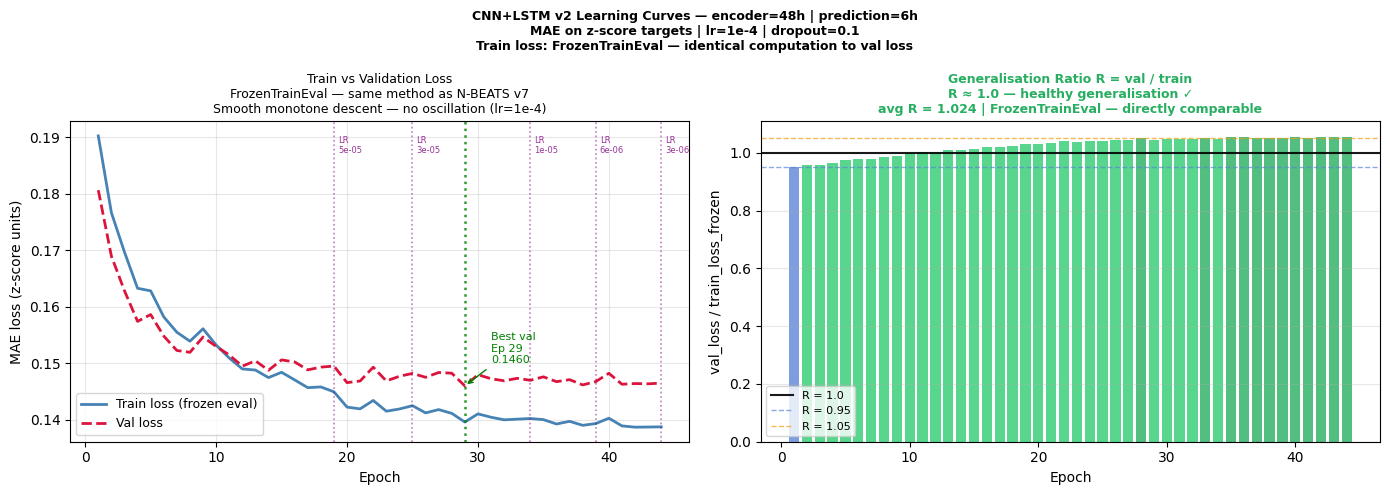

Saved: /home/iai-labor/traffic_project/CNN_LSTM_figures_v2/cnn_lstm_v2_loss_curves.png

Loss curve summary:
  Train: 0.1902 → 0.1388
  Val:   0.1806 → 0.1460
  Best val epoch: 29  loss=0.1460
  Avg R ratio:    1.024
  Diagnosis:      R ≈ 1.0 — healthy generalisation ✓


In [7]:
# ── Load training history ──────────────────────────────────────────────────────
with open(os.path.join(RESULTS_DIR, "cnn_lstm_v2_history.json")) as f:
    history = json.load(f)

train_loss = np.array(history["train_loss_frozen"])
val_loss   = np.array(history["val_loss"])
lr_history = np.array(history["lr"])
epochs     = np.arange(1, len(train_loss) + 1)

print(f"Epochs logged: {len(train_loss)}")
print(f"Train: {train_loss[0]:.4f} → {train_loss[-1]:.4f}")
print(f"Val:   {val_loss[0]:.4f} → {val_loss.min():.4f}")
print(f"Best val epoch: {int(np.argmin(val_loss)) + 1}  "
      f"loss={val_loss.min():.4f}")

# ── Figure ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    "CNN+LSTM v2 Learning Curves — encoder=48h | prediction=6h\n"
    "MAE on z-score targets | lr=1e-4 | dropout=0.1\n"
    "Train loss: FrozenTrainEval — identical computation to val loss",
    fontsize=9, fontweight="bold"
)

# ── Panel 1: Train vs Val loss ─────────────────────────────────────────────────
ax1 = axes[0]
ax1.plot(epochs, train_loss,
         color="steelblue", linewidth=2.0, label="Train loss (frozen eval)")
ax1.plot(epochs, val_loss,
         color="crimson", linewidth=2.0,
         linestyle="--", label="Val loss")

best_epoch = int(np.argmin(val_loss)) + 1
best_loss  = float(val_loss.min())
ax1.axvline(x=best_epoch, color="green",
            linestyle=":", linewidth=1.8, alpha=0.8)
ax1.annotate(
    f"Best val\nEp {best_epoch}\n{best_loss:.4f}",
    xy=(best_epoch, best_loss),
    xytext=(best_epoch + 2, best_loss + 0.004),
    fontsize=8, color="green",
    arrowprops=dict(arrowstyle="->", color="green", lw=1.0)
)

# LR reduction markers
y_top    = float(train_loss.max())
prev_lr  = None
for i, lr in enumerate(lr_history):
    if prev_lr is not None and lr < prev_lr - 1e-10:
        ax1.axvline(x=epochs[i], color="purple",
                    linestyle=":", linewidth=1.2, alpha=0.5)
        ax1.text(epochs[i] + 0.3, y_top,
                 f"LR\n{lr:.0e}",
                 fontsize=6, color="purple",
                 va="top", alpha=0.8)
    prev_lr = lr

ax1.set_xlabel("Epoch", fontsize=10)
ax1.set_ylabel("MAE loss (z-score units)", fontsize=10)
ax1.set_title(
    "Train vs Validation Loss\n"
    "FrozenTrainEval — same method as N-BEATS v7\n"
    "Smooth monotone descent — no oscillation (lr=1e-4)",
    fontsize=9
)
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

# ── Panel 2: Generalisation ratio R ───────────────────────────────────────────
ax2 = axes[1]
ratio     = val_loss / train_loss
avg_ratio = float(ratio.mean())

bar_colors = [
    "#5c85d6" if r < 0.95 else
    "#2ecc71" if r < 1.05 else
    "#27ae60" if r < 1.50 else
    "#f39c12"
    for r in ratio
]
ax2.bar(epochs, ratio, color=bar_colors, alpha=0.80)
ax2.axhline(y=1.0, color="black",
            linewidth=1.5, alpha=0.9, label="R = 1.0")
ax2.axhline(y=0.95, color="#5c85d6",
            linewidth=1.0, linestyle="--",
            alpha=0.7, label="R = 0.95")
ax2.axhline(y=1.05, color="#f39c12",
            linewidth=1.0, linestyle="--",
            alpha=0.7, label="R = 1.05")

val_vals = val_loss
slope    = float(np.polyfit(np.arange(len(val_vals[-10:])),
                             val_vals[-10:], 1)[0])
rising   = slope > 1e-4

if rising:
    diagnosis, col = "Val loss rising — overfitting", "#e74c3c"
elif avg_ratio < 0.95:
    diagnosis, col = "Val < Train — data difficulty difference", "#5c85d6"
elif avg_ratio < 1.05:
    diagnosis, col = "R ≈ 1.0 — healthy generalisation ✓", "#27ae60"
else:
    diagnosis, col = "Val > Train — dropout effect (expected)", "#27ae60"

ax2.set_title(
    f"Generalisation Ratio R = val / train\n"
    f"{diagnosis}\n"
    f"avg R = {avg_ratio:.3f} | FrozenTrainEval — directly comparable",
    fontsize=9, color=col, fontweight="bold"
)
ax2.set_xlabel("Epoch", fontsize=10)
ax2.set_ylabel("val_loss / train_loss_frozen", fontsize=10)
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "cnn_lstm_v2_loss_curves.png")
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")
print(f"\nLoss curve summary:")
print(f"  Train: {train_loss[0]:.4f} → {train_loss[-1]:.4f}")
print(f"  Val:   {val_loss[0]:.4f} → {val_loss.min():.4f}")
print(f"  Best val epoch: {best_epoch}  loss={best_loss:.4f}")
print(f"  Avg R ratio:    {avg_ratio:.3f}")
print(f"  Diagnosis:      {diagnosis}")

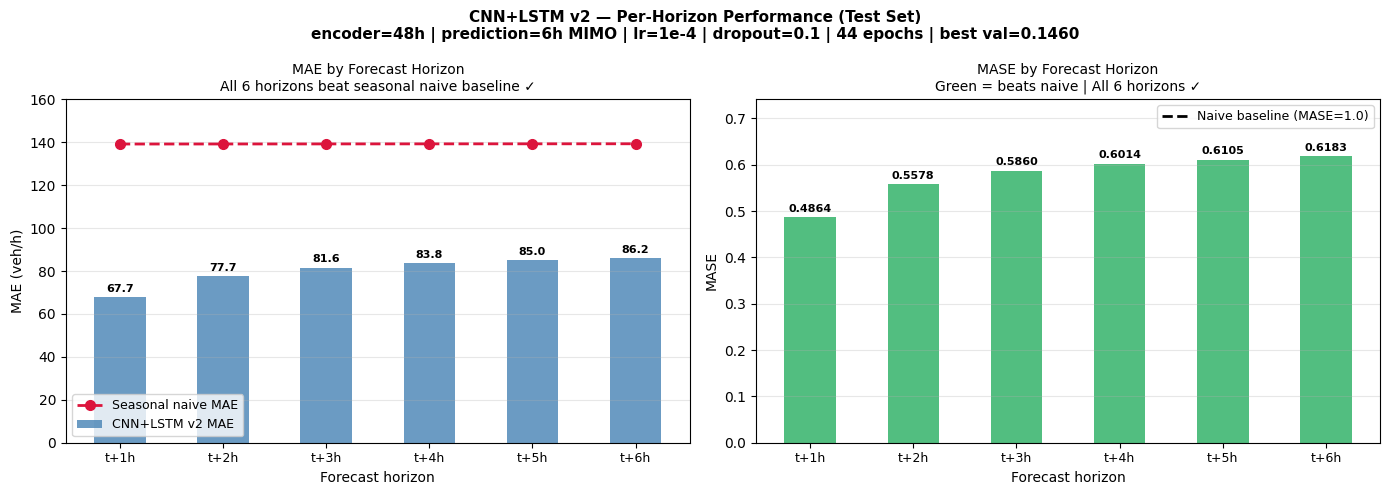

Saved: /home/iai-labor/traffic_project/CNN_LSTM_figures_v2/cnn_lstm_v2_horizon_metrics.png

Horizon       MAE     MASE     vs naive
----------------------------------------
t+1h        67.71   0.4864     51.4% better
t+2h        77.67   0.5578     44.2% better
t+3h        81.61   0.5860     41.4% better
t+4h        83.77   0.6014     39.9% better
t+5h        85.04   0.6105     38.9% better
t+6h        86.15   0.6183     38.2% better
Overall     80.33   0.5767


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    "CNN+LSTM v2 — Per-Horizon Performance (Test Set)\n"
    "encoder=48h | prediction=6h MIMO | lr=1e-4 | dropout=0.1 | "
    "44 epochs | best val=0.1460",
    fontsize=11, fontweight="bold"
)

horizons   = [f"t+{h+1}h" for h in range(CFG["max_prediction_length"])]
maes       = [horizon_metrics[h]["MAE"]  for h in horizons]
mases      = [horizon_metrics[h]["MASE"] for h in horizons]
naive_maes = [horizon_naive[h]           for h in horizons]
x          = np.arange(len(horizons))

# ── Panel 1: MAE vs Naive MAE ─────────────────────────────────────────────────
ax1 = axes[0]
bars = ax1.bar(x, maes, color="steelblue",
               alpha=0.8, width=0.5, label="CNN+LSTM v2 MAE")
ax1.plot(x, naive_maes, color="crimson", linewidth=2.0,
         marker="o", markersize=7, linestyle="--",
         label="Seasonal naive MAE")

for bar, mae in zip(bars, maes):
    ax1.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 1.5,
             f"{mae:.1f}", ha="center", va="bottom",
             fontsize=8, fontweight="bold")

ax1.set_xticks(x)
ax1.set_xticklabels(horizons, fontsize=9)
ax1.set_xlabel("Forecast horizon", fontsize=10)
ax1.set_ylabel("MAE (veh/h)", fontsize=10)
ax1.set_title(
    "MAE by Forecast Horizon\n"
    "All 6 horizons beat seasonal naive baseline ✓",
    fontsize=10
)
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3, axis="y")
ax1.set_ylim(0, max(max(maes), max(naive_maes)) * 1.15)

# ── Panel 2: MASE ─────────────────────────────────────────────────────────────
ax2 = axes[1]
bar_colors = ["#27ae60" if m < 1.0 else "#e74c3c" for m in mases]
bars2 = ax2.bar(x, mases, color=bar_colors, alpha=0.8, width=0.5)
ax2.axhline(y=1.0, color="black", linewidth=2.0,
            linestyle="--", label="Naive baseline (MASE=1.0)")

for bar, mase in zip(bars2, mases):
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.008,
             f"{mase:.4f}", ha="center", va="bottom",
             fontsize=8, fontweight="bold")

ax2.set_xticks(x)
ax2.set_xticklabels(horizons, fontsize=9)
ax2.set_xlabel("Forecast horizon", fontsize=10)
ax2.set_ylabel("MASE", fontsize=10)
ax2.set_title(
    "MASE by Forecast Horizon\n"
    "Green = beats naive | All 6 horizons ✓",
    fontsize=10
)
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3, axis="y")
ax2.set_ylim(0, max(mases) * 1.20)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "cnn_lstm_v2_horizon_metrics.png")
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")
print()
print(f"{'Horizon':<8} {'MAE':>8} {'MASE':>8} {'vs naive':>12}")
print(f"{'-'*40}")
for h in horizons:
    m           = horizon_metrics[h]
    improvement = (1 - m["MASE"]) * 100
    print(f"{h:<8} {m['MAE']:>8.2f} {m['MASE']:>8.4f} "
          f"  {improvement:>6.1f}% better")
print(f"{'Overall':<8} {overall['MAE']:>8.2f} {overall['MASE']:>8.4f}")

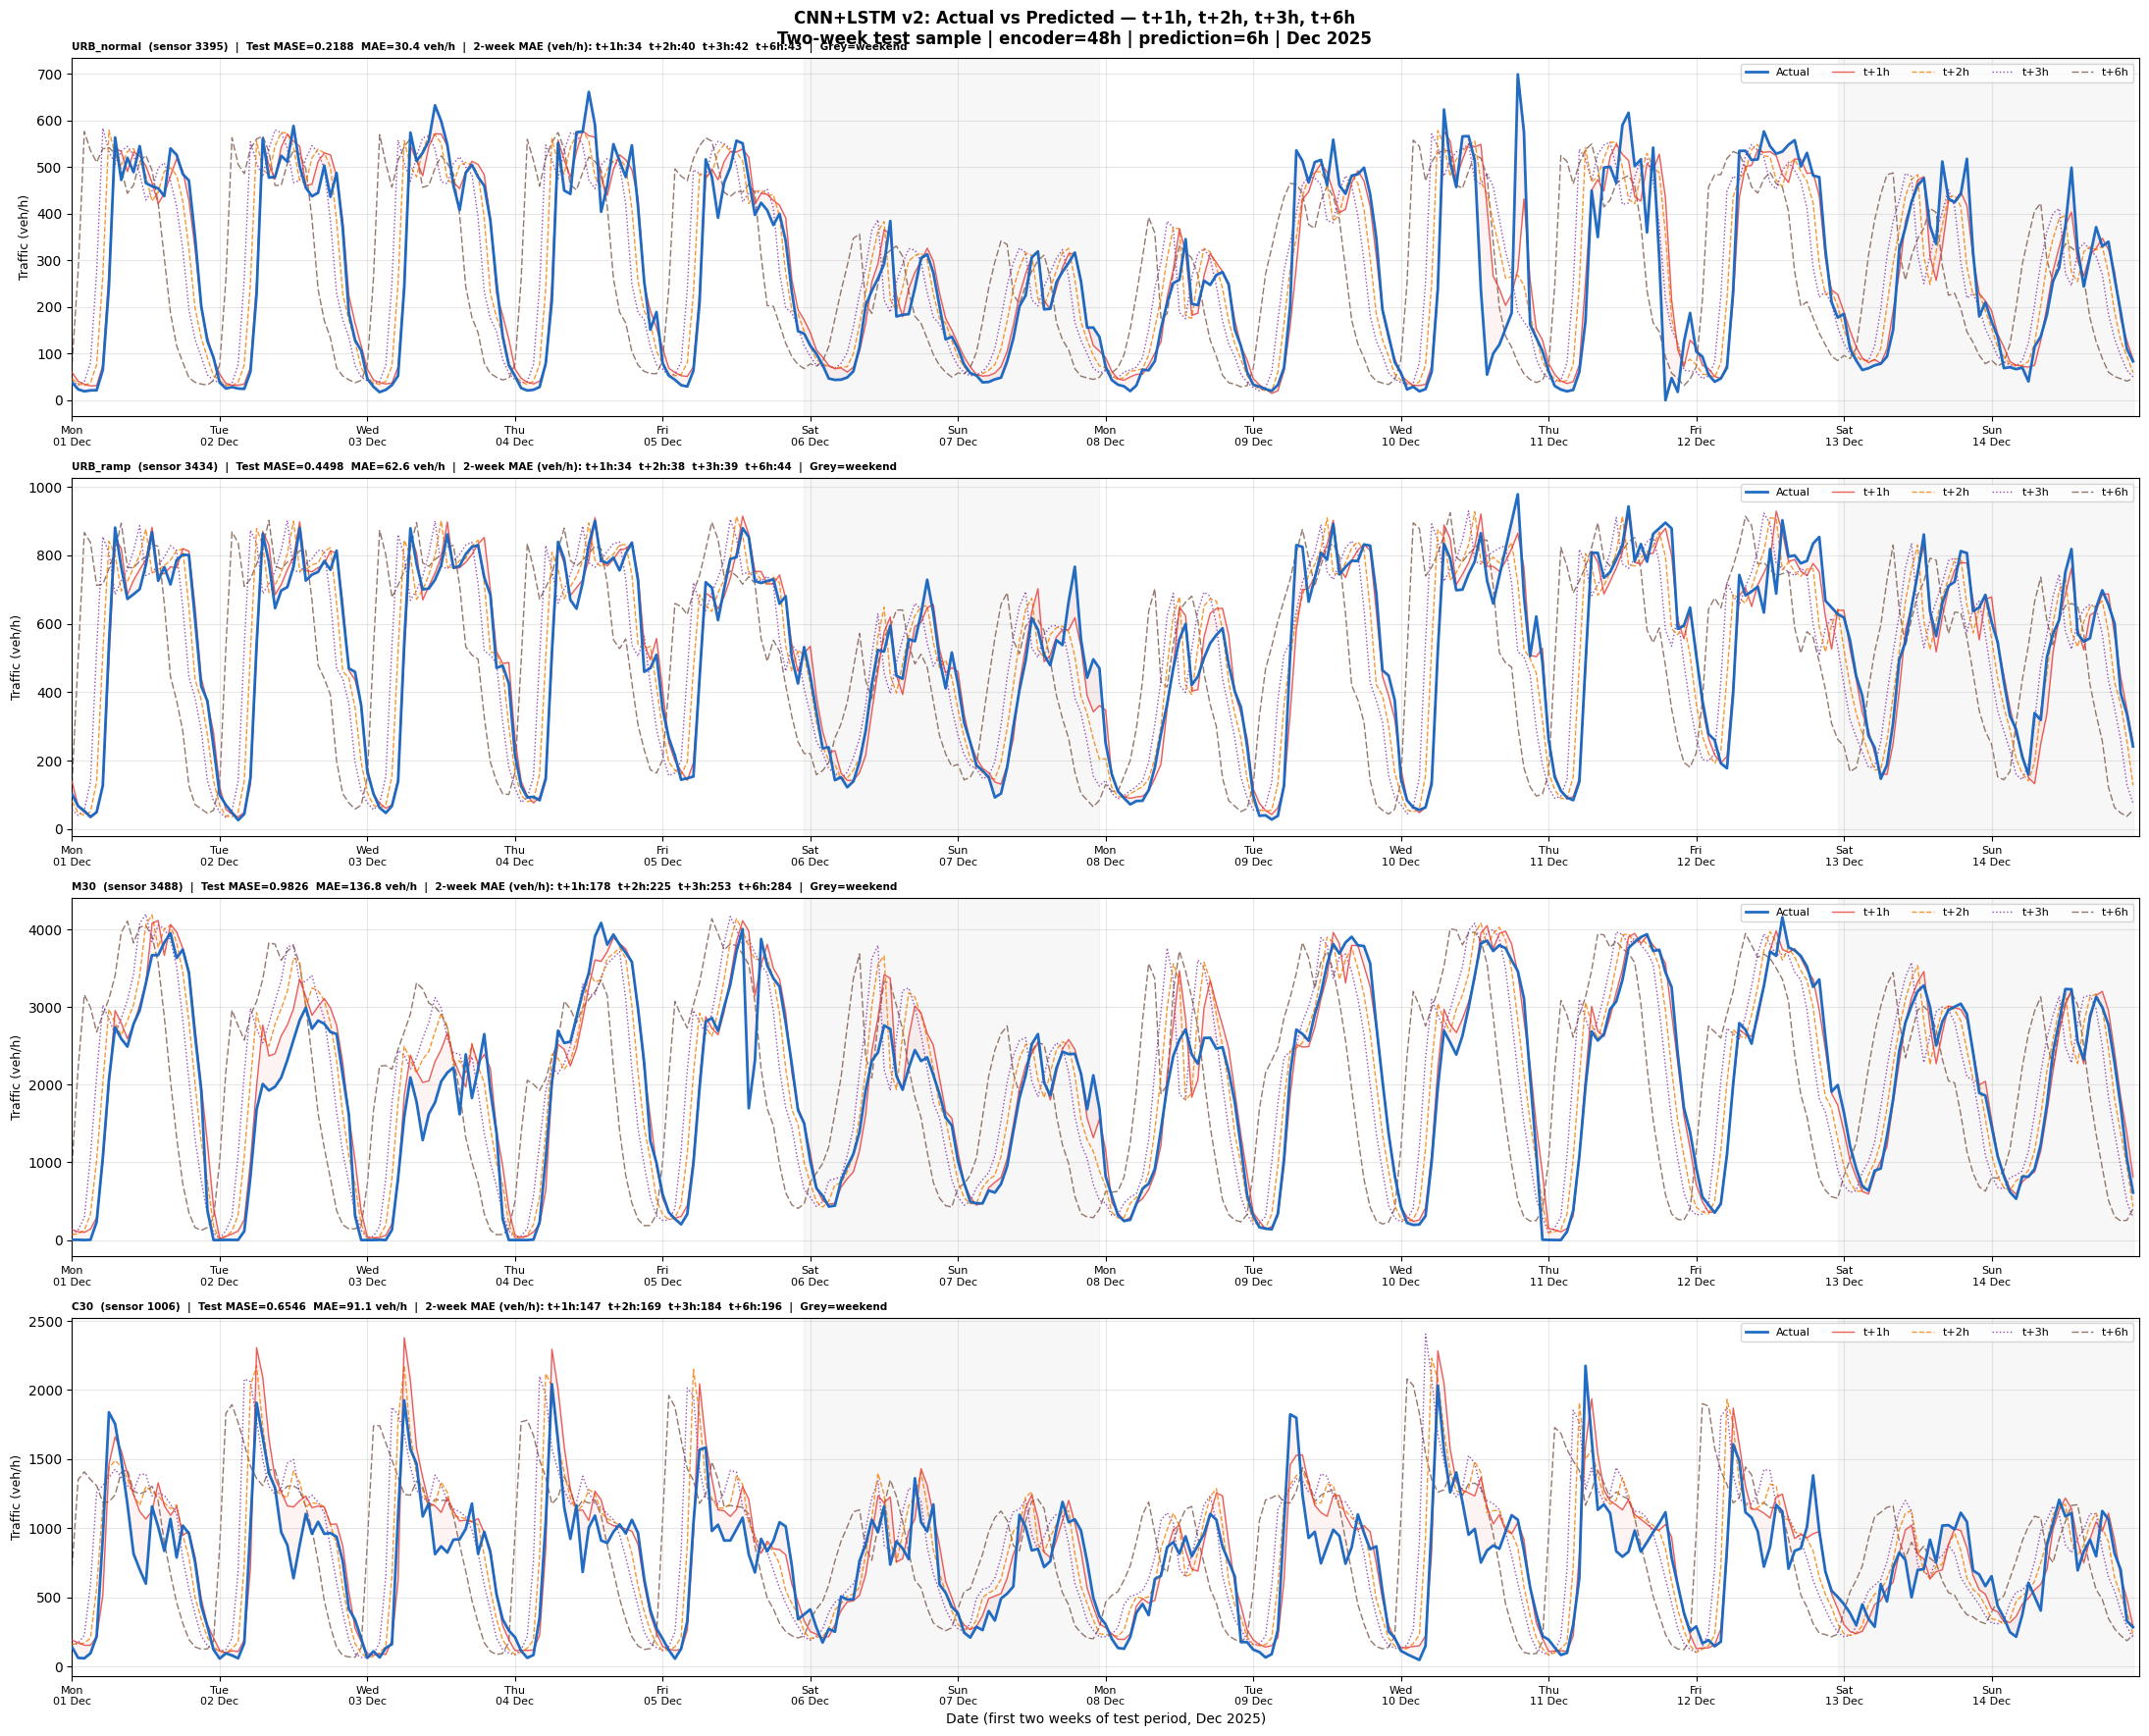

Saved: /home/iai-labor/traffic_project/CNN_LSTM_figures_v2/cnn_lstm_v2_twoweek_4horizons.png


In [9]:
PLOT_SENSORS = {
    "URB_normal": 3395,
    "URB_ramp":   3434,
    "M30":        3488,
    "C30":        1006,
}
TWO_WEEKS = 24 * 14

SELECTED_HORIZONS = {
    "t+1h": (0, "#E53935", "-"),
    "t+2h": (1, "#F57C00", "--"),
    "t+3h": (2, "#7B1FA2", ":"),
    "t+6h": (5, "#795548", (0, (5, 2))),
}

fig, axes = plt.subplots(4, 1, figsize=(22, 18), sharex=False)
fig.suptitle(
    "CNN+LSTM v2: Actual vs Predicted — t+1h, t+2h, t+3h, t+6h\n"
    "Two-week test sample | encoder=48h | prediction=6h | Dec 2025",
    fontsize=12, fontweight="bold"
)

for ax, (label, sensor_id) in zip(axes, PLOT_SENSORS.items()):
    sid_str        = str(sensor_id)
    sensor_mask    = sensor_arr == sid_str
    sensor_indices = np.where(sensor_mask)[0]

    if len(sensor_indices) == 0:
        ax.set_title(f"{label} — sensor {sensor_id} not found")
        continue

    n_show   = min(TWO_WEEKS, len(sensor_indices))
    plot_idx = sensor_indices[:n_show]

    actuals_t1 = actual_veh[plot_idx, 0]
    window_dts = pd.to_datetime([
        time_origin + pd.Timedelta(hours=int(ts_arr[i]))
        for i in plot_idx
    ])
    window_dts_list = list(window_dts)
    x = np.arange(n_show)

    ax.plot(x, actuals_t1,
            color="#1565C0", linewidth=2.0,
            alpha=0.95, label="Actual", zorder=7)

    for h_label, (h_idx, color, style) in SELECTED_HORIZONS.items():
        ax.plot(x, pred_veh[plot_idx, h_idx],
                color=color, linewidth=1.0,
                linestyle=style, alpha=0.80,
                label=h_label, zorder=6 - h_idx)

    ax.fill_between(x, actuals_t1, pred_veh[plot_idx, 0],
                    alpha=0.06, color="#E53935", zorder=2)

    dow_vals = pd.Series(window_dts).dt.dayofweek
    i = 0
    while i < len(window_dts_list):
        if dow_vals.iloc[i] == 5:
            j = i
            while j < len(window_dts_list) and \
                    dow_vals.iloc[j] in [5, 6]:
                j += 1
            ax.axvspan(i, j, alpha=0.06, color="gray", zorder=0)
            i = j
        else:
            i += 1

    mae_str = "  ".join([
        f"{h_label}:{np.mean(np.abs(pred_veh[plot_idx, h_idx] - actual_veh[plot_idx, h_idx])):.0f}"
        for h_label, (h_idx, _, _) in SELECTED_HORIZONS.items()
    ])
    mase_sc = subclass_results.get(label, {}).get("MASE", 0)
    mae_sc  = subclass_results.get(label, {}).get("MAE",  0)

    day_ticks  = list(range(0, n_show, 24))
    day_labels = [
        window_dts_list[t].strftime("%a\n%d %b")
        for t in day_ticks if t < n_show
    ]
    ax.set_xticks(day_ticks[:len(day_labels)])
    ax.set_xticklabels(day_labels, fontsize=8)
    ax.set_xlim(0, n_show)

    ax.set_title(
        f"{label}  (sensor {sensor_id})  |  "
        f"Test MASE={mase_sc:.4f}  MAE={mae_sc:.1f} veh/h  |  "
        f"2-week MAE (veh/h): {mae_str}  |  Grey=weekend",
        fontsize=7.5, fontweight="bold", loc="left"
    )
    ax.set_ylabel("Traffic (veh/h)", fontsize=9)
    ax.legend(loc="upper right", fontsize=8, ncol=5)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel(
    "Date (first two weeks of test period, Dec 2025)", fontsize=10
)
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "cnn_lstm_v2_twoweek_4horizons.png")
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

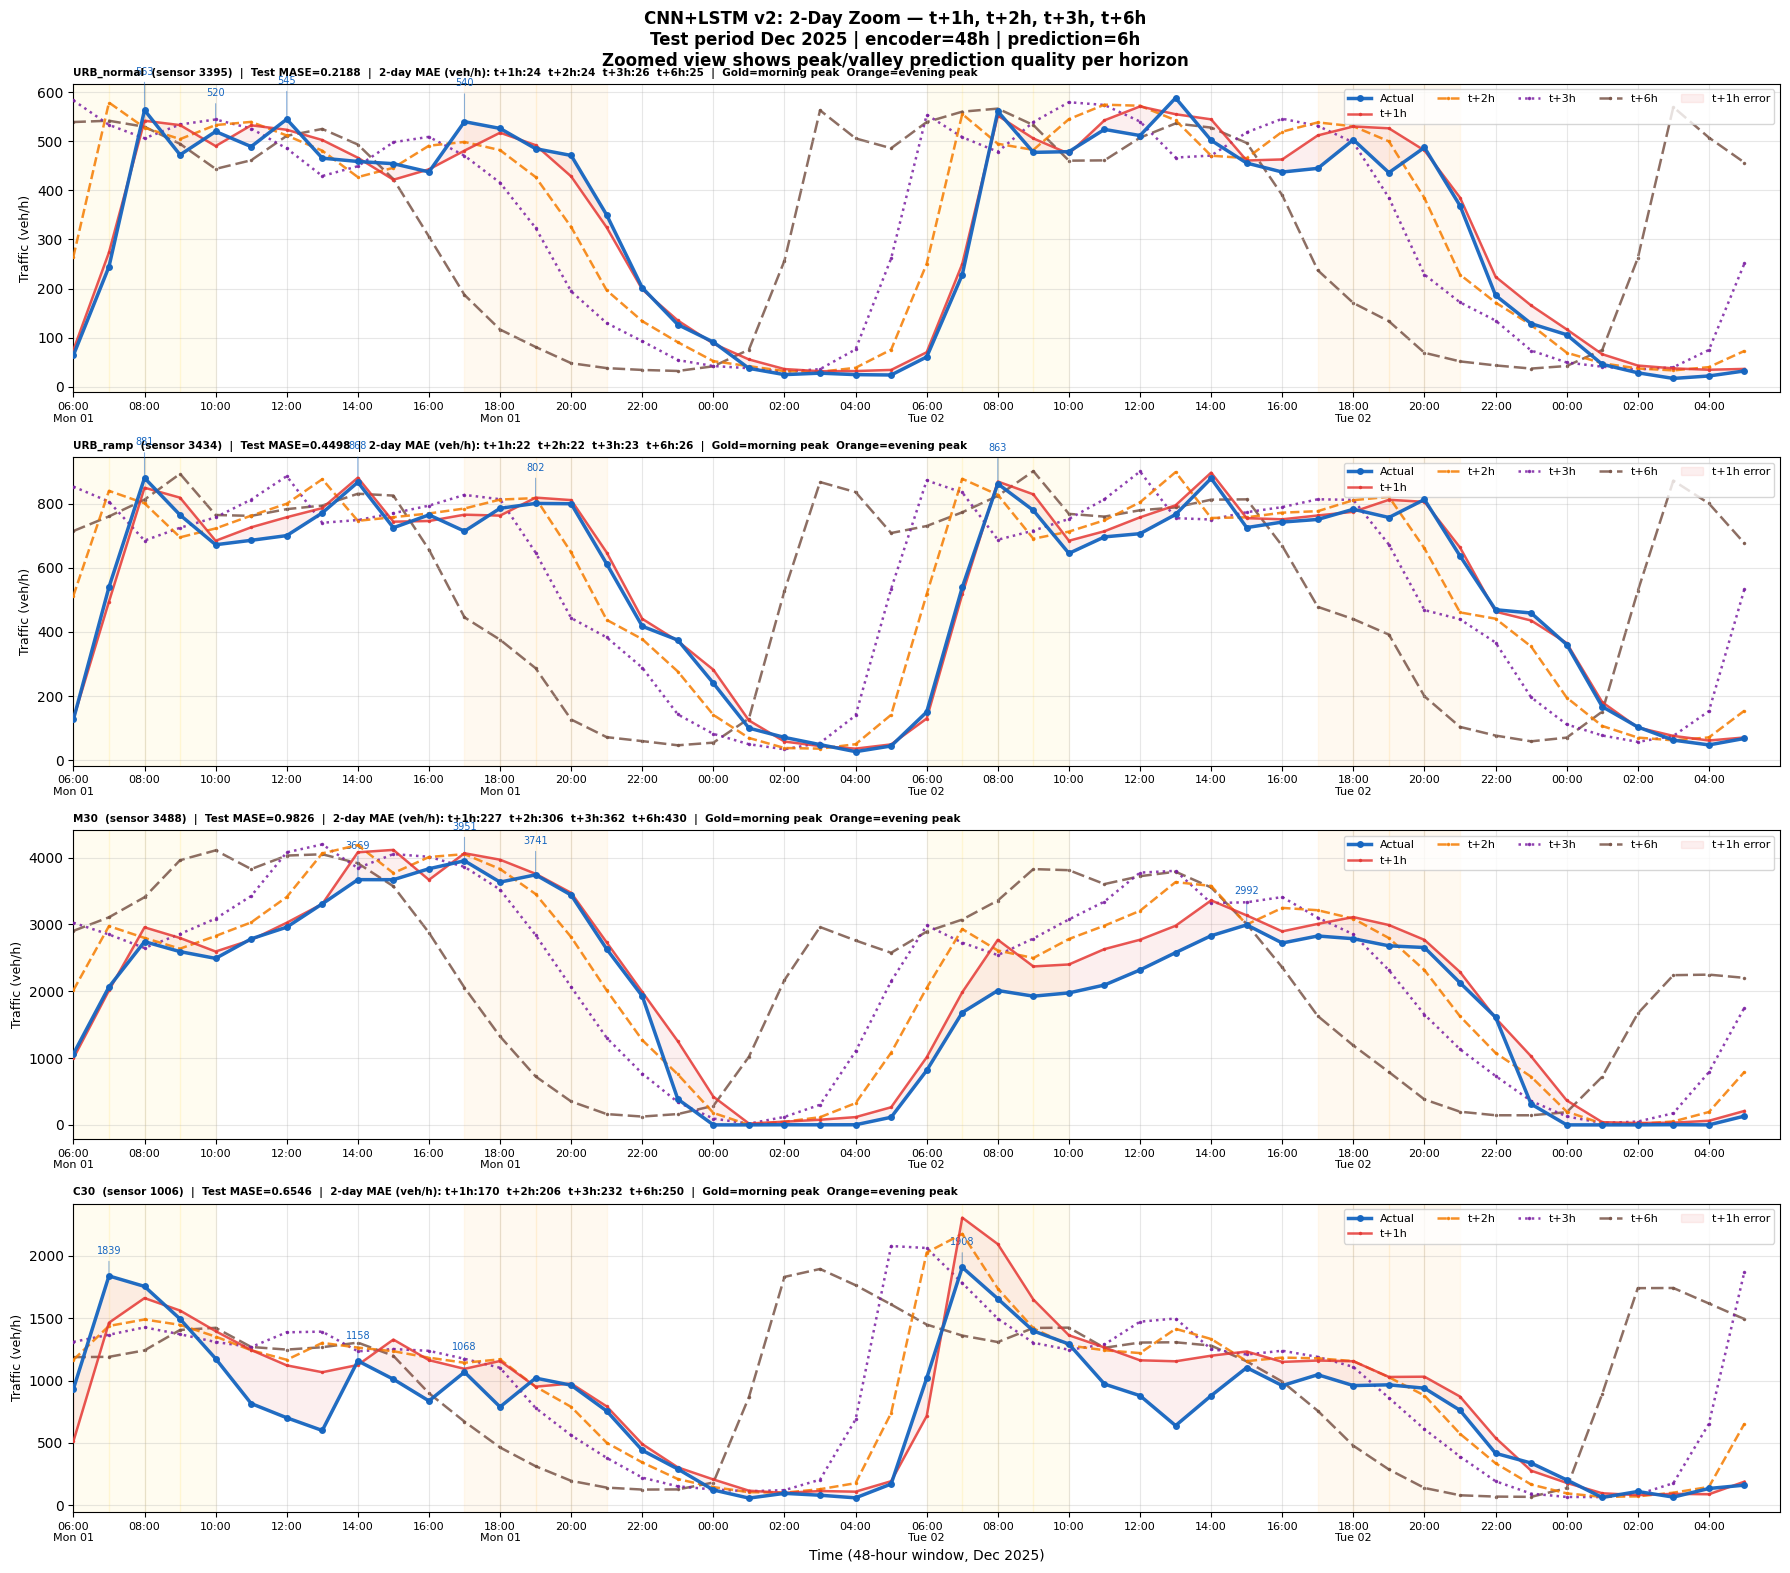

Saved: /home/iai-labor/traffic_project/CNN_LSTM_figures_v2/cnn_lstm_v2_twoday_4horizons.png


In [10]:
TWO_DAYS = 24 * 2

fig, axes = plt.subplots(4, 1, figsize=(18, 16), sharex=False)
fig.suptitle(
    "CNN+LSTM v2: 2-Day Zoom — t+1h, t+2h, t+3h, t+6h\n"
    "Test period Dec 2025 | encoder=48h | prediction=6h\n"
    "Zoomed view shows peak/valley prediction quality per horizon",
    fontsize=12, fontweight="bold"
)

for ax, (label, sensor_id) in zip(axes, PLOT_SENSORS.items()):
    sid_str        = str(sensor_id)
    sensor_mask    = sensor_arr == sid_str
    sensor_indices = np.where(sensor_mask)[0]

    if len(sensor_indices) == 0:
        ax.set_title(f"{label} — sensor {sensor_id} not found")
        continue

    # Find Monday 06:00 start
    start_idx = None
    for idx in sensor_indices:
        t0_hours = int(ts_arr[idx])
        dt       = time_origin + pd.Timedelta(hours=t0_hours)
        if dt.dayofweek == 0 and dt.hour == 6:
            start_idx = idx
            break
    if start_idx is None:
        start_idx = sensor_indices[0]

    start_pos = np.where(sensor_indices == start_idx)[0][0]
    n_show    = min(TWO_DAYS, len(sensor_indices) - start_pos)
    plot_idx  = sensor_indices[start_pos: start_pos + n_show]

    actuals_t1 = actual_veh[plot_idx, 0]
    window_dts = pd.to_datetime([
        time_origin + pd.Timedelta(hours=int(ts_arr[i]))
        for i in plot_idx
    ])
    window_dts_list = list(window_dts)
    x = np.arange(n_show)

    ax.plot(x, actuals_t1,
            color="#1565C0", linewidth=2.5,
            alpha=0.95, label="Actual",
            zorder=7, marker="o", markersize=4)

    for h_label, (h_idx, color, style) in SELECTED_HORIZONS.items():
        ax.plot(x, pred_veh[plot_idx, h_idx],
                color=color, linewidth=1.8,
                linestyle=style, alpha=0.85,
                label=h_label, zorder=6 - h_idx,
                marker=".", markersize=3)

    ax.fill_between(x, actuals_t1, pred_veh[plot_idx, 0],
                    alpha=0.08, color="#E53935",
                    zorder=2, label="t+1h error")

    for i, dt in enumerate(window_dts_list):
        if 6 <= dt.hour <= 9:
            ax.axvspan(i, i + 1, alpha=0.06, color="gold",   zorder=0)
        elif 17 <= dt.hour <= 20:
            ax.axvspan(i, i + 1, alpha=0.06, color="orange", zorder=0)

    hour_ticks  = list(range(0, n_show, 2))
    hour_labels = [
        window_dts_list[t].strftime("%H:%M\n%a %d")
        if t % 12 == 0
        else window_dts_list[t].strftime("%H:%M")
        for t in hour_ticks if t < n_show
    ]
    ax.set_xticks(hour_ticks[:len(hour_labels)])
    ax.set_xticklabels(hour_labels, fontsize=8)
    ax.set_xlim(0, n_show)

    peak_threshold = np.percentile(actuals_t1, 75)
    peak_signal    = np.concatenate(
        [[actuals_t1[0]], actuals_t1, [actuals_t1[-1]]]
    )
    peaks = np.where(
        (actuals_t1 > peak_threshold) &
        (np.diff(np.sign(np.diff(peak_signal))) < 0)
    )[0]
    for pk in peaks[:4]:
        ax.annotate(
            f"{actuals_t1[pk]:.0f}",
            xy=(pk, actuals_t1[pk]),
            xytext=(pk, actuals_t1[pk] + actuals_t1.std() * 0.35),
            fontsize=7, color="#1565C0", ha="center",
            arrowprops=dict(arrowstyle="-", color="#1565C0",
                            lw=0.8, alpha=0.5)
        )

    mae_str = "  ".join([
        f"{h_label}:{np.mean(np.abs(pred_veh[plot_idx, h_idx] - actual_veh[plot_idx, h_idx])):.0f}"
        for h_label, (h_idx, _, _) in SELECTED_HORIZONS.items()
    ])
    mase_sc = subclass_results.get(label, {}).get("MASE", 0)

    ax.set_title(
        f"{label}  (sensor {sensor_id})  |  "
        f"Test MASE={mase_sc:.4f}  |  "
        f"2-day MAE (veh/h): {mae_str}  |  "
        f"Gold=morning peak  Orange=evening peak",
        fontsize=7.5, fontweight="bold", loc="left"
    )
    ax.set_ylabel("Traffic (veh/h)", fontsize=9)
    ax.legend(loc="upper right", fontsize=8, ncol=5)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel(
    "Time (48-hour window, Dec 2025)", fontsize=10
)
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "cnn_lstm_v2_twoday_4horizons.png")
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

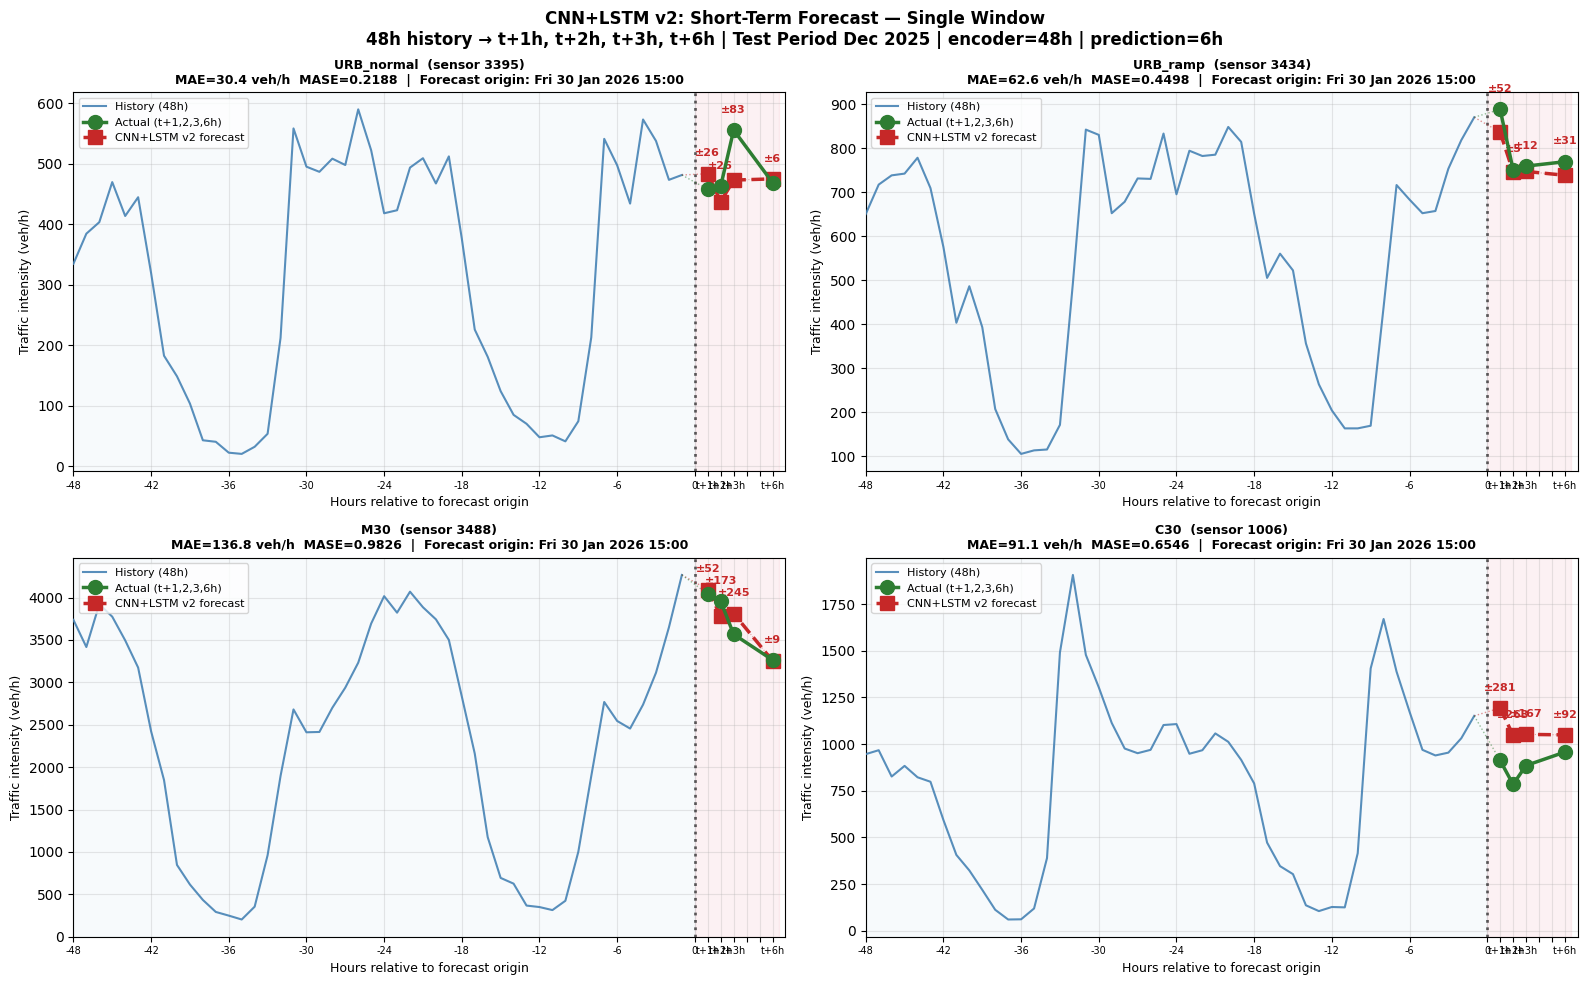

Saved: /home/iai-labor/traffic_project/CNN_LSTM_figures_v2/cnn_lstm_v2_snapshot_4horizons.png

All CNN+LSTM v2 evaluation figures saved:
  ✓  cnn_lstm_v2_loss_curves.png
  ✓  cnn_lstm_v2_horizon_metrics.png
  ✓  cnn_lstm_v2_twoweek_4horizons.png
  ✓  cnn_lstm_v2_twoday_4horizons.png
  ✓  cnn_lstm_v2_snapshot_4horizons.png


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle(
    "CNN+LSTM v2: Short-Term Forecast — Single Window\n"
    "48h history → t+1h, t+2h, t+3h, t+6h | "
    "Test Period Dec 2025 | encoder=48h | prediction=6h",
    fontsize=12, fontweight="bold"
)

SELECTED_SNAP = {
    "t+1h": (0, "#E53935", "-"),
    "t+2h": (1, "#F57C00", "--"),
    "t+3h": (2, "#7B1FA2", ":"),
    "t+6h": (5, "#795548", (0, (5, 2))),
}

for ax, (label, sensor_id) in zip(axes.flat, PLOT_SENSORS.items()):
    sid_str        = str(sensor_id)
    sensor_mask    = sensor_arr == sid_str
    sensor_indices = np.where(sensor_mask)[0]

    if len(sensor_indices) == 0:
        ax.set_title(f"{label} — sensor not found")
        continue

    # Find weekday afternoon window with meaningful traffic
    chosen_idx = None
    search_start = len(sensor_indices) // 3
    for idx in sensor_indices[search_start: search_start + 500]:
        t_pred = int(ts_arr[idx])
        dt     = time_origin + pd.Timedelta(hours=t_pred)
        if (dt.dayofweek < 5 and
                14 <= dt.hour <= 18 and
                actual_veh[idx].mean() > 100):
            chosen_idx = idx
            break
    if chosen_idx is None:
        chosen_idx = sensor_indices[len(sensor_indices) // 2]

    pred_vals   = pred_veh[chosen_idx]
    actual_vals = actual_veh[chosen_idx]

    # 48h encoder history from df
    t_start   = int(ts_arr[chosen_idx]) - CFG["max_encoder_length"]
    t_end     = int(ts_arr[chosen_idx]) - 1
    sensor_df = df[
        (df["SENSOR_ID"] == sensor_id) &
        (df["time_idx"].between(t_start, t_end))
    ].sort_values("time_idx")
    history = sensor_df["target"].values

    if len(history) < CFG["max_encoder_length"]:
        history = np.pad(
            history,
            (CFG["max_encoder_length"] - len(history), 0),
            constant_values=0
        )

    history_x      = np.arange(-CFG["max_encoder_length"], 0)
    snap_h_indices = [0, 1, 2, 5]
    future_x       = np.array([1, 2, 3, 6])

    ax.plot(history_x, history,
            color="steelblue", linewidth=1.5,
            alpha=0.9, label="History (48h)", zorder=3)

    actual_plot = actual_vals[snap_h_indices]
    pred_plot   = pred_vals[snap_h_indices]

    ax.plot(future_x, actual_plot,
            color="#2E7D32", linewidth=2.5,
            marker="o", markersize=10,
            label="Actual (t+1,2,3,6h)", zorder=5)
    ax.plot(future_x, pred_plot,
            color="#C62828", linewidth=2.5,
            marker="s", markersize=10,
            linestyle="--",
            label="CNN+LSTM v2 forecast", zorder=4)

    # Dotted bridge t+3 → t+6
    ax.plot([3, 6], [actual_vals[2], actual_vals[5]],
            color="#2E7D32", linewidth=0.8,
            linestyle=":", alpha=0.4, zorder=3)
    ax.plot([3, 6], [pred_vals[2], pred_vals[5]],
            color="#C62828", linewidth=0.8,
            linestyle=":", alpha=0.4, zorder=3)

    # Connect history to first forecast point
    ax.plot([history_x[-1], future_x[0]],
            [history[-1], pred_plot[0]],
            color="#C62828", linewidth=1.0,
            linestyle=":", alpha=0.5, zorder=3)
    ax.plot([history_x[-1], future_x[0]],
            [history[-1], actual_plot[0]],
            color="#2E7D32", linewidth=1.0,
            linestyle=":", alpha=0.5, zorder=3)

    ax.axvline(x=0, color="black", linestyle=":",
               linewidth=2.0, alpha=0.6)
    ax.axvspan(-CFG["max_encoder_length"], 0,
               alpha=0.04, color="steelblue")
    ax.axvspan(0, 6.5, alpha=0.06, color="crimson")

    y_range = (
        max(history.max(), actual_plot.max(), pred_plot.max()) -
        min(history.min(), actual_plot.min(), pred_plot.min())
    )
    for i, fx in enumerate(future_x):
        err  = abs(pred_plot[i] - actual_plot[i])
        ypos = max(pred_plot[i], actual_plot[i]) + y_range * 0.05
        ax.annotate(
            f"±{err:.0f}",
            xy=(fx, ypos),
            fontsize=8, color="#C62828",
            ha="center", fontweight="bold"
        )

    xtick_hist   = list(range(-48, 0, 6))
    xtick_labels = (
        [str(h) for h in xtick_hist] +
        ["0", "t+1h", "t+2h", "t+3h", "", "", "t+6h"]
    )
    ax.set_xticks(xtick_hist + [0, 1, 2, 3, 4, 5, 6])
    ax.set_xticklabels(xtick_labels, fontsize=7)
    ax.set_xlim(-48, 7)

    forecast_dt = (
        time_origin + pd.Timedelta(hours=int(ts_arr[chosen_idx]))
    ).strftime("%a %d %b %Y %H:%M")

    mae_sc  = subclass_results.get(label, {}).get("MAE",  0)
    mase_sc = subclass_results.get(label, {}).get("MASE", 0)

    ax.set_title(
        f"{label}  (sensor {sensor_id})\n"
        f"MAE={mae_sc:.1f} veh/h  MASE={mase_sc:.4f}  |  "
        f"Forecast origin: {forecast_dt}",
        fontsize=9, fontweight="bold"
    )
    ax.set_xlabel("Hours relative to forecast origin", fontsize=9)
    ax.set_ylabel("Traffic intensity (veh/h)", fontsize=9)
    ax.legend(fontsize=8, loc="upper left")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "cnn_lstm_v2_snapshot_4horizons.png")
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")
print()
print("All CNN+LSTM v2 evaluation figures saved:")
for fname in [
    "cnn_lstm_v2_loss_curves.png",
    "cnn_lstm_v2_horizon_metrics.png",
    "cnn_lstm_v2_twoweek_4horizons.png",
    "cnn_lstm_v2_twoday_4horizons.png",
    "cnn_lstm_v2_snapshot_4horizons.png",
]:
    fpath = os.path.join(FIGURES_DIR, fname)
    exists = "✓" if os.path.exists(fpath) else "✗ MISSING"
    print(f"  {exists}  {fname}")